In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_curve,roc_auc_score,precision_recall_curve,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [36]:
X, y = make_classification(n_samples=1000,n_features=5,n_informative=3,n_redundant=1,weights=[0.95, 0.05],random_state=42)

print("Dataset Shape:", X.shape)
print("Class Distribution:")
print(pd.Series(y).value_counts())

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

Dataset Shape: (1000, 5)
Class Distribution:
0    948
1     52
Name: count, dtype: int64


In [37]:
log_model = LogisticRegression(random_state=42)

rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

xgb_model = XGBClassifier(n_estimators=100,random_state=42,eval_metric="logloss")

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print("\nAll three models trained successfully!")


All three models trained successfully!


In [38]:
y_prob_log = log_model.predict_proba(X_test)[:, 1]

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("\nPrediction probabilities generated successfully!")

print("\nLogistic Regression:", y_prob_log[:5])
print("Random Forest:", y_prob_rf[:5])
print("XGBoost:", y_prob_xgb[:5])

fpr_log, tpr_log, thresholds_log = roc_curve(y_test, y_prob_log)

fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)

fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, y_prob_xgb)


Prediction probabilities generated successfully!

Logistic Regression: [0.00988146 0.07360571 0.3688556  0.00327653 0.0397385 ]
Random Forest: [0.03 0.   0.24 0.   0.  ]
XGBoost: [0.00972275 0.00093366 0.05618169 0.00024435 0.00257934]


In [39]:
auc_log = roc_auc_score(y_test, y_prob_log)

auc_rf = roc_auc_score(y_test, y_prob_rf)

auc_xgb = roc_auc_score(y_test, y_prob_xgb)

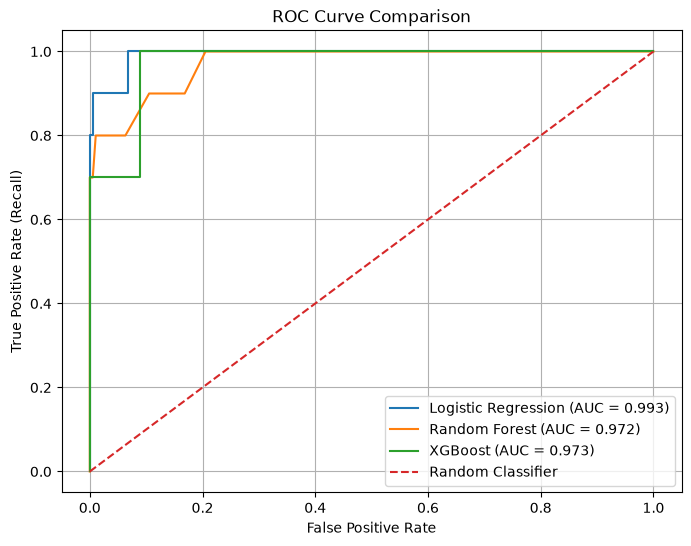

In [40]:
plt.figure(figsize=(8, 6))

plt.plot(fpr_log,tpr_log,label=f"Logistic Regression (AUC = {auc_log:.3f})")
plt.plot(fpr_rf,tpr_rf,label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot(fpr_xgb,tpr_xgb,label=f"XGBoost (AUC = {auc_xgb:.3f})")
plt.plot([0, 1],[0, 1],linestyle="--",label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()



In [41]:
print("\nAUC Scores:")

print("Logistic Regression:", round(auc_log, 3))
print("Random Forest:", round(auc_rf, 3))
print("XGBoost:", round(auc_xgb, 3))



AUC Scores:
Logistic Regression: 0.993
Random Forest: 0.972
XGBoost: 0.973


In [42]:
precision, recall, thresholds = precision_recall_curve(y_test,y_prob_log)

# Find thresholds where recall is at least 80%
valid_indices = np.where(recall[:-1] >= 0.80)[0]

# Select the threshold with the highest precision
best_index = valid_indices[np.argmax(precision[valid_indices])]

best_threshold = thresholds[best_index]
best_recall = recall[best_index]
best_precision = precision[best_index]

print("Selected Threshold:", round(best_threshold, 3))
print("Recall:", round(best_recall, 3))
print("Precision:", round(best_precision, 3))

Selected Threshold: 0.187
Recall: 0.8
Precision: 1.0


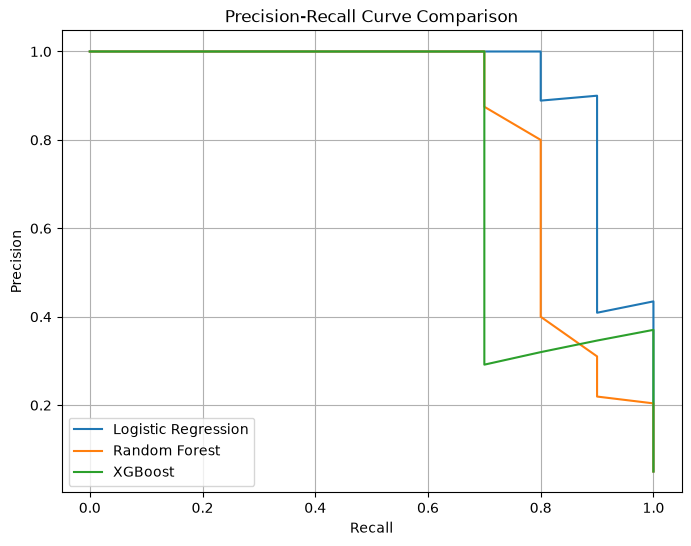

In [43]:
# Calculate Precision-Recall values for all three models
precision_log, recall_log, _ = precision_recall_curve(y_test, y_prob_log)
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_prob_rf)
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)


# Plot Precision-Recall curves
plt.figure(figsize=(8, 6))

plt.plot(recall_log, precision_log, label="Logistic Regression")

plt.plot(recall_rf, precision_rf, label="Random Forest")

plt.plot(recall_xgb, precision_xgb, label="XGBoost")


plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [44]:
# Get class predictions from all three models
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
y_pred_xgb = xgb_model.predict(X_test)

# Calculating F1 scores
f1_log = f1_score(y_test, y_pred_log)
f1_rf = f1_score(y_test, y_pred_rf)
f1_xgb = f1_score(y_test, y_pred_xgb)

# Creating comparison table
results = pd.DataFrame({"Model": ["Logistic Regression", "Random Forest", "XGBoost"],"AUC": [auc_log, auc_rf, auc_xgb],"F1": [f1_log, f1_rf, f1_xgb]})

# Display table
print("Model Performance Comparison")
display(results.round(3))

Model Performance Comparison


,Model,AUC,F1
0,Logistic Regression,0.993,0.667
1,Random Forest,0.972,0.667
2,XGBoost,0.973,0.750


## When to Use F1 and AUC

1. F1-score is useful when we need a balance between precision and recall, especially for imbalanced datasets.
2. F1-score is preferred when false positives and false negatives are both important.
3. AUC is useful for evaluating how well a model separates positive and negative classes across different thresholds.
4. AUC is preferred when comparing overall classification performance without selecting a fixed threshold.